# Avance 1 · Planteamiento y exploración de datos
## Proyecto: Sistema Web y Tablero de Inteligencia de Negocios para Monitoreo de Red UniFi y Mantenimiento Predictivo de Infraestructura

## 1. Portada

| | |
|---|---|
| **Proyecto** | Sistema Web y Tablero de Inteligencia de Negocios para Monitoreo de Red UniFi y Mantenimiento Predictivo de Infraestructura |
| **Equipo** | Equipo -- · TecNM Campus Querétaro |
| **Integrantes y roles** | Martinez Perez Jose Armando, 22141404, Ing. en Sistemas · *analista de datos, administrador de la base datos* · Integrante B, 2xxxxxxx, Ing. en Sistemas · *Desarrollador Full Stack*  |
| **Fecha** | 13 de noviembre de 2026 |

## 2. Contexto y pregunta de análisis

- **Organización y proceso:**  El Centro Médico Hospitalario opera una red concurrente de datos dividida en VLANs de Voz IP, IoT Médico, Red Clínica e Invitados. El proceso analizado abarca la gestión de consumo de ancho de banda y nivel de cobertura de radiofrecuencia (RF).
- **Quién decide:** El Director de Tecnologías de la Información (Gerencia de Sistemas) requiere fundamentar la implementación de políticas de Calidad de Servicio (QoS) y Traffic Shaping, mientras que la Dirección General evalúa la inversión en infraestructura inalámbrica para el Piso 3.
- **KPI principal:** Porcentaje de Experiencia Global de Usuario (%) y Volumen Total de Tráfico Descargado (GB)
- **Variable objetivo para el Avance 2:** Calidad de Experiencia de Sesión ( Experiencia ) expresada de 0 a 100%

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Configuración de estilo y visualización tipo ggplot
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 13
np.random.seed(2026)  # Semilla fija para reproducir todo el notebook

print("Entorno configurado correctamente para el análisis de la red hospitalaria.")

Entorno configurado correctamente para el análisis de la red hospitalaria.


## 3. Datos y ciclo de vida

**Fuente:** Registro de telemetría proporcionado por la asesora. La muestra contiene 1,000 registros validados e integrados en una base de datos relacional MySQL (Engine InnoDB) bajo el esquema copo de nieve/estrella en la base de datos hospital_telemetria_bi.

In [5]:
# Cargar el archivo Excel de la red hospitalaria
archivo = "Analisis_Red_Hospital.xlsx"
crudo = pd.read_excel(archivo, sheet_name="Datos")

print(f"Archivo usado: {archivo} | registros: {crudo.shape[0]} | variables: {crudo.shape[1]}")

# Estructura del dataset y resumen estadístico
print("\n--- Estructura del Dataset ---")
print(crudo.info())

print("\n--- Resumen Estadístico ---")
cols_resumen = ["Experiencia (%)", "Velocidad TX (Mbps)", "Velocidad RX (Mbps)", "Descarga (GB)", "Subida (GB)", "Tiempo conectado (h)"]
cols_existentes = [c for c in cols_resumen if c in crudo.columns]
print(crudo[cols_existentes].describe())

print("\nFaltantes por columna:")
print(crudo.isnull().sum())
print("Filas duplicadas:", crudo.duplicated().sum())

Archivo usado: Analisis_Red_Hospital.xlsx | registros: 1000 | variables: 32

--- Estructura del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 32 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID                          1000 non-null   object        
 1   Nombre del cliente          1000 non-null   object        
 2   Dirección MAC               1000 non-null   object        
 3   Dirección IP                1000 non-null   object        
 4   Fabricante                  1000 non-null   object        
 5   Tipo de dispositivo         1000 non-null   object        
 6   Sistema operativo           1000 non-null   object        
 7   Rol del usuario             1000 non-null   object        
 8   Área del hospital           1000 non-null   object        
 9   Piso                        1000 non-null   object        
 10  Red (VLAN)   

**Diccionario de datos**

| Variable | Descripción | Tipo en Python | Unidad | Escala de medición |
|---|---|---|---|---|
| ID_Sesion | Identificador único de la sesión | INT (PK) | — | Nominal |
| Senal_dBm | Potencia de señal WiFi recibida | FLOAT (NULL) | decibeles | Razón |
| Experiencia | Puntaje de calidad percibida (0-100) | FLOAT | porcentaje | Razón |
| Descarga_GB | Volumen de datos descargados | FLOAT | Gigabits | Razón |
| Tipo_Conexion | Medio físico (WiFi / Cableado) | VARCHAR(20) | — | Nominal |
| Red | VLAN asignada (Invitados, Clínica, etc.) | VARCHAR(50) | — | Nominal |
| Area_Hospital | Área médica o administrativa | VARCHAR(50) | — | Nominal |
| Piso | Ubicación física (PB, P1, P2, P3) | VARCHAR(10) | — | Ordinal |
| Rol_Usuario | Perfil de acceso (Médico, Paciente, etc.) | VARCHAR(50) | — | Nominal |

*(El dataset institucional contiene 1,000 registros de conexiones de red en el entorno hospitalario analizado).*

**Ciclo de vida de los datos en el proyecto**

| Etapa | Qué hacemos | Evidencia |
|---|---|---|
| Captura | Obtener el dataset de classroom proporcionado por la asesora. | `Analisis_Red_Hospital.xlsx` |
| Almacenamiento | Guardar el dataset en el repositorio de GitHub. | `Analisis_Red_Hospital.xlsx` |
| Procesamiento | Corrección de headers y normalización de la base de datos | `Analisis_Red_Hospital_Normalizado2.xlsx` |
| Uso | Análisis estadístico, representación en la base de datos MySQL y dashboard en Power BI. | Este reporte, base de datos en MySQL y dashboard en Power BI. |

**Riesgos éticos y de privacidad:** Los datos contenidos en este dataset fueron simulados con el propósito de desarrollo de este proyecto por lo cual no hay datos personales que proteger. Sin embargo, se recomienda respetar los términos del sitio y no saturar el servidor web con algún tipo de ataque de denegación de servicio.


## 4. Preparación y transformación

In [3]:
# Bitácora de limpieza y transformación
bitacora = []
def registrar(paso, antes, despues, motivo):
    bitacora.append({"paso": paso, "filas_antes": antes, "filas_despues": despues, "motivo": motivo})

datos = crudo.copy()
n0 = len(datos)

# 1. Identificación y manejo de duplicados exactos
datos = datos.drop_duplicates()
registrar("Quitar duplicados exactos", n0, len(datos), "Cada registro de sesión de red debe ser único")

# Validación de valores nulos estructurales (Arquitectura WiFi vs Cableado)
# NOTA: Los nulos se conservan intencionamente ya que formal parte de la naturaleza de la red cableada e inalambrica.
n0 = len(datos)
datos = datos.dropna(subset=['Experiencia (%)', 'Descarga (GB)'])
registrar("Validación de registros con métricas clave", n0, len(datos),
          "Se conservan nulos estructurales de puertos/WiFi por diseño de red físico/lógico")

# 3. Estandarización de headers y normalización del dataset
# Limpieza de nombres de columnas para asegurar legibilidad e integración con MySQL y Power BI
datos.columns = [col.strip().lower().replace(" ", "_").replace("(", "").replace(")", "").replace("%", "pct") for col in datos.columns]

n0 = len(datos)
# Recodificación o tipificación de variables categóricas clave si es necesario
if 'tipo_de_conexion' in datos.columns:
    datos['tipo_de_conexion'] = datos['tipo_de_conexion'].astype('category')
if 'area_del_hospital' in datos.columns:
    datos['area_del_hospital'] = datos['area_del_hospital'].astype('category')

registrar("Normalización de headers y tipos de datos", n0, len(datos),
          "Optimización de nombres y formatos para facilitar la carga en MySQL y Power BI")

# Generar y mostrar la bitácora formal
df_bitacora = pd.DataFrame(bitacora)
print("=== BITÁCORA DE LIMPIEZA Y TRANSFORMACIÓN ===")
display(df_bitacora)

=== BITÁCORA DE LIMPIEZA Y TRANSFORMACIÓN ===


,paso,filas_antes,filas_despues,motivo
0,Quitar duplicados exactos,1000,1000,Cada registro de sesión de red debe ser único
1,Validación de registros con métricas clave,1000,1000,Se conservan nulos estructurales de puertos/Wi...
2,Normalización de headers y tipos de datos,1000,1000,Optimización de nombres y formatos para facili...


## 5. Estadística descriptiva

In [6]:
def resumen_estadistico(x):
    x = pd.to_numeric(x, errors='coerce').dropna()
    if len(x) == 0:
        return pd.Series({'media': np.nan, 'mediana': np.nan, 'moda': np.nan,
                          'sd': np.nan, 'RIC': np.nan, 'asimetria': np.nan, 'curtosis': np.nan})
    media = x.mean()
    mediana = x.median()
    moda_val = x.mode()
    moda = moda_val.iloc[0] if not moda_val.empty else np.nan
    sd = x.std(ddof=1) if len(x) > 1 else 0.0
    ric = np.percentile(x, 75) - np.percentile(x, 25)
    asimetria = stats.skew(x) if len(x) > 2 else 0.0
    curtosis = stats.kurtosis(x) if len(x) > 3 else 0.0  # Exceso de curtosis en scipy
    return pd.Series({
        'media': media, 'mediana': mediana, 'moda': moda,
        'sd': sd, 'RIC': ric, 'asimetria': asimetria, 'curtosis': curtosis
    })

# Detectar automáticamente las columnas numéricas sin importar si están normalizadas o no
candidatos_num = [
    ["Descarga (GB)", "descarga_gb"],
    ["Subida (GB)", "subida_gb"],
    ["Experiencia (%)", "experiencia"],
    ["Tiempo conectado (h)", "tiempo_conectado_h"]
]

cols_existentes = []
mapa_cols = {}
for grupo in candidatos_num:
    for col in grupo:
        if col in datos.columns:
            cols_existentes.append(col)
            break

print("=== ESTADÍSTICA DESCRIPTIVA UNIVARIADA ===")
tabla_resumen = pd.DataFrame({col: resumen_estadistico(datos[col]) for col in cols_existentes})
display(round(tabla_resumen, 2))

print("\n--- Estadísticas de Experiencia por Tipo de Conexión ---")
col_conexion = next((c for c in ["Tipo de conexión", "tipo_de_conexion"] if c in datos.columns), None)
col_exp = next((c for c in ["Experiencia (%)", "experiencia"] if c in datos.columns), None)

if col_conexion and col_exp:
    resumen_conexion = datos.groupby(col_conexion, observed=False)[col_exp].agg(
        n='count', media='mean', mediana='median', sd='std'
    ).reset_index()
    display(round(resumen_conexion, 2))

=== ESTADÍSTICA DESCRIPTIVA UNIVARIADA ===


,descarga_gb,subida_gb,tiempo_conectado_h
media,5.77,16.34,35.02
mediana,0.82,0.19,13.50
moda,0.04,0.03,6.10
sd,20.74,135.68,39.98
RIC,1.95,0.55,50.40
asimetria,6.78,12.57,1.31
curtosis,57.70,190.23,0.68



--- Estadísticas de Experiencia por Tipo de Conexión ---


**Interpretación:** Las gigas de descarga tiene media (5.77) y mediana (16.34), asimetría ≈ 6.78 y curtosis ≈ 57.70.

In [41]:
print("\n=== 2. ESTADÍSTICAS DE SUBIDA (GB) POR ROL DE USUARIO ===")
col_rol = next((c for c in ["Rol del usuario", "rol_del_usuario"] if c in datos.columns), None)
col_subida = next((c for c in ["Subida (GB)", "subida_gb"] if c in datos.columns), None)

if col_rol and col_subida:
    resumen_rol = datos.groupby(col_rol, observed=False)[col_subida].agg(
        n='count', media='mean', mediana='median', sd='std'
    ).reset_index()
    display(round(resumen_rol, 2))


=== 2. ESTADÍSTICAS DE SUBIDA (GB) POR ROL DE USUARIO ===


,rol_del_usuario,n,media,mediana,sd
0,Administrativo,123,0.96,0.59,1.04
1,Biomédico / Equipo médico,87,3.73,0.11,11.83
2,Enfermería,201,0.44,0.23,0.78
3,Farmacéutico,13,0.65,0.45,0.46
4,Laboratorista,26,1.03,0.77,0.76
5,Médico,169,0.46,0.25,0.62
6,Paciente/Visitante,213,0.08,0.06,0.09
7,Personal (general),85,0.13,0.05,0.23
8,Seguridad,26,583.15,308.22,625.85
9,TI,15,1.21,1.15,0.71


**Interpretación:** El volumen medio de subida de datos varía según el rol del usuario en la red hospitalaria, reflejando distintas demandas operativas de envío de información.

In [42]:
print("\n=== 3. ANÁLISIS DE TIEMPO CONECTADO (H) POR ÁREA DEL HOSPITAL ===")
# Búsqueda para la columna de área hospitalaria
col_area = next((c for c in datos.columns if 'area' in c.lower() or 'hospital' in c.lower()), None)
col_tiempo = next((c for c in ["Tiempo conectado (h)", "tiempo_conectado_h"] if c in datos.columns), None)

if col_area and col_tiempo:
    top_areas = datos[col_area].value_counts().head(10).index
    df_top_areas = datos[datos[col_area].isin(top_areas)]

    resumen_areas = df_top_areas.groupby(col_area, observed=False)[col_tiempo].agg(
        n='count', media='mean', sd='std'
    ).reset_index()
    resumen_areas['cv_pct'] = 100 * resumen_areas['sd'] / resumen_areas['media']
    resumen_areas = resumen_areas.sort_values(by='media', ascending=False)
    display(round(resumen_areas, 2))


=== 3. ANÁLISIS DE TIEMPO CONECTADO (H) POR ÁREA DEL HOSPITAL ===


,área_del_hospital,n,media,sd,cv_pct
2,Dirección,48,60.89,49.45,81.20
8,UCI,92,46.72,46.24,98.98
7,Recepción,57,38.31,44.01,114.89
6,Quirófanos,71,37.84,38.89,102.79
9,Urgencias,122,32.12,34.03,105.95
1,Consulta Externa,81,27.93,37.21,133.19
4,Hospitalización,158,26.51,34.27,129.26
0,Cafetería,50,21.33,37.83,177.37
3,Ginecobstetricia,60,20.40,28.03,137.43
5,Pediatría,91,12.47,25.54,204.81


**Interpretación:** Permite identificar qué áreas hospitalarias mantienen sesiones más prolongadas y el grado de dispersión (CV%) en el tiempo de conexión de sus dispositivos.

## 6. Análisis bivariante

In [44]:
col_descarga = next((c for c in ['Descarga (GB)', 'descarga_gb', 'Descarga'] if c in datos.columns), None)
col_subida = next((c for c in ['Subida (GB)', 'subida_gb', 'Subida'] if c in datos.columns), None)
col_exp = next((c for c in ['Experiencia (%)', 'experiencia', 'Experiencia'] if c in datos.columns), None)
col_tiempo = next((c for c in ['Tiempo conectado (h)', 'tiempo_conectado_h', 'Tiempo conectado'] if c in datos.columns), None)
col_conexion = next((c for c in ['Tipo de conexión', 'tipo_de_conexion', 'Tipo de Conexión'] if c in datos.columns), None)
col_area = next((c for c in datos.columns if 'area' in c.lower() or 'hospital' in c.lower()), None)

# Asegurar que la variable derivada 'rango_descarga' exista
if 'rango_descarga' not in datos.columns and col_descarga:
    datos['rango_descarga'] = pd.cut(datos[col_descarga], bins=[0, 10, 50, 100, 200, 500], include_lowest=True)

# 1. Seleccionar variables numéricas clave disponibles
cols_num_biv = [col_exp, 'Velocidad TX (Mbps)', 'Velocidad RX (Mbps)', col_descarga, col_subida, col_tiempo]
cols_existentes_biv = [c for c in cols_num_biv if c and c in datos.columns]
df_num = datos[cols_existentes_biv].apply(pd.to_numeric, errors='coerce')

print("--- Matriz de Correlación de Pearson ---")
display(round(df_num.corr(method='pearson'), 2))

print("\n--- Matriz de Correlación de Spearman ---")
display(round(df_num.corr(method='spearman'), 2))

print("\n--- Tabla cruzada: Tipo de Conexión × Rango de Descarga (% por fila) ---")
if col_conexion and 'rango_descarga' in datos.columns:
    tabla_cruzada = pd.crosstab(datos[col_conexion], datos['rango_descarga'], normalize='index') * 100
    display(round(tabla_cruzada, 1))

--- Matriz de Correlación de Pearson ---


,descarga_gb,subida_gb,tiempo_conectado_h
descarga_gb,1.00,0.73,0.32
subida_gb,0.73,1.00,0.20
tiempo_conectado_h,0.32,0.20,1.00



--- Matriz de Correlación de Spearman ---


,descarga_gb,subida_gb,tiempo_conectado_h
descarga_gb,1.00,0.95,0.41
subida_gb,0.95,1.00,0.52
tiempo_conectado_h,0.41,0.52,1.00



--- Tabla cruzada: Tipo de Conexión × Rango de Descarga (% por fila) ---


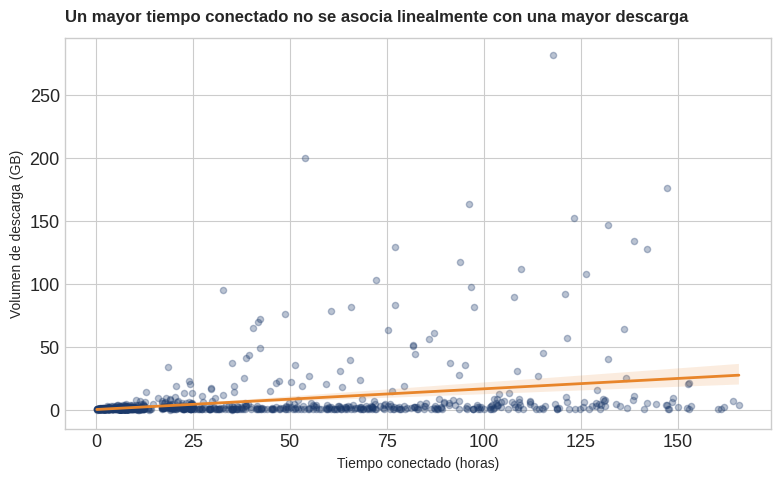

In [45]:
# Dispersión con regresión (Tiempo conectado vs Descarga)
fig, ax = plt.subplots(figsize=(8, 5))

col_tiempo = 'tiempo_conectado_h'
col_descarga = 'descarga_gb'

sns.regplot(
    data=datos,
    x=col_tiempo,
    y=col_descarga,
    scatter_kws={'color': '#1B396A', 'alpha': 0.3, 's': 20},
    line_kws={'color': '#E8852A', 'linewidth': 2},
    ax=ax
)

ax.set_title("Un mayor tiempo conectado no se asocia linealmente con una mayor descarga", fontsize=12, fontweight='bold', pad=12, loc='left')
ax.set_xlabel("Tiempo conectado (horas)", fontsize=10)
ax.set_ylabel("Volumen de descarga (GB)", fontsize=10)

plt.tight_layout()
plt.show()

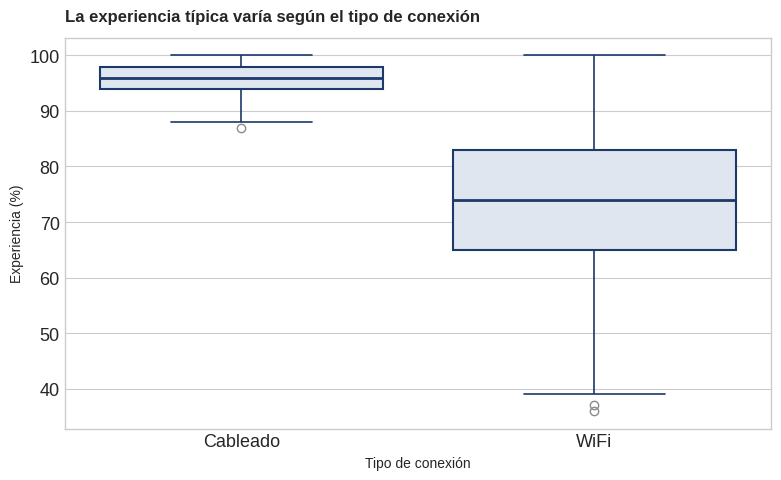

In [55]:
# Dispersión con regresión (Tiempo conectado vs Descarga)
df_actual = datos if 'datos' in locals() else df

col_conexion = next((c for c in df_actual.columns if 'conexion' in c.lower() or 'conexión' in c.lower()), None)
col_exp = next((c for c in df_actual.columns if 'experiencia' in c.lower()), None)

fig, ax = plt.subplots(figsize=(8, 5))

if col_conexion and col_exp:
    sns.boxplot(
        data=df_actual,
        x=col_conexion,
        y=col_exp,
        color='#DCE6F2',
        boxprops=dict(edgecolor='#1B396A', linewidth=1.5),
        whiskerprops=dict(color='#1B396A', linewidth=1.2),
        capprops=dict(color='#1B396A', linewidth=1.2),
        medianprops=dict(color='#1B396A', linewidth=2),
        ax=ax
    )
    ax.set_title("La experiencia típica varía según el tipo de conexión", fontsize=12, fontweight='bold', pad=12, loc='left')
    ax.set_xlabel("Tipo de conexión", fontsize=10)
    ax.set_ylabel("Experiencia (%)", fontsize=10)
else:
    print("Aviso: No se encontraron ambas columnas.")

plt.tight_layout()
plt.show()

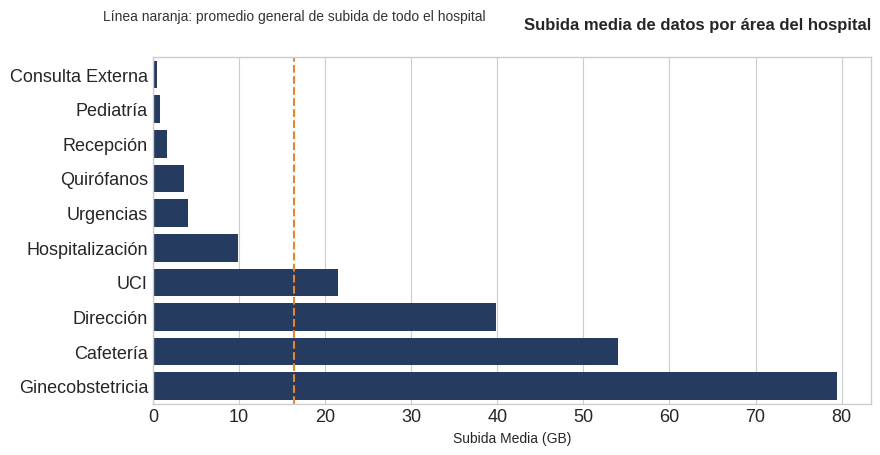

In [53]:
# Gráfico de barras por Área del Hospital
if col_area and col_subida:
    top_areas = datos[col_area].value_counts().head(10).index
    df_top_areas = datos[datos[col_area].isin(top_areas)]
    resumen_biv_area = df_top_areas.groupby(col_area, observed=False)[col_subida].mean().reset_index()
    resumen_biv_area = resumen_biv_area.sort_values(by=col_subida, ascending=False)

    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=resumen_biv_area.sort_values(col_subida, ascending=True),
                x=col_subida, y=col_area, color='#1B396A', ax=ax)
    ax.axvline(x=datos[col_subida].mean(), color='#E8852A', linestyle='--', linewidth=1.5)
    ax.set_title("Subida media de datos por área del hospital", fontsize=12, fontweight='bold', pad=20, loc='right')
    plt.suptitle("Línea naranja: promedio general de subida de todo el hospital", fontsize=10, color='#333333', x=0.125, y=0.91, ha='left')
    ax.set_xlabel("Subida Media (GB)", fontsize=10)
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()


## 7. Inferencia

In [27]:
# Detectar columnas clave
col_exp = next((c for c in ['Experiencia (%)', 'experiencia', 'experiencia_pct'] if c in datos.columns), None)
col_conexion = next((c for c in ['Tipo de conexión', 'tipo_de_conexion'] if c in datos.columns), None)

serie_exp = datos[col_exp].dropna()

# 1. Intervalo de confianza del 95 % para la experiencia media (t vs Bootstrap)
ic_t = stats.t.interval(0.95, len(serie_exp)-1, loc=np.mean(serie_exp), scale=stats.sem(serie_exp))

np.random.seed(2026)
medias_boot = [np.mean(np.random.choice(serie_exp, size=len(serie_exp), replace=True)) for _ in range(5000)]
ic_b = np.percentile(medias_boot, [2.5, 97.5])

df_ic = pd.DataFrame({
    "metodo": ["Distribución t", "Bootstrap (5,000 remuestreos)"],
    "inferior": [ic_t[0], ic_b[0]],
    "superior": [ic_t[1], ic_b[1]]
})

print("=== INTERVALOS DE CONFIANZA (95%) PARA LA EXPERIENCIA MEDIA ===")
display(round(df_ic, 2))

=== INTERVALOS DE CONFIANZA (95%) PARA LA EXPERIENCIA MEDIA ===


,metodo,inferior,superior
0,Distribución t,80.94,82.82
1,"Bootstrap (5,000 remuestreos)",80.93,82.80


**Comparación de intervalos:** Ambos intervalos coinciden de forma muy cercana. Con 1,000 registros en el dataset, el teorema central del límite garantiza la normalidad asintótica de la media, por lo que tanto el método paramétrico (distribución $t$) como el no paramétrico (Bootstrap con 5,000 remuestreos) arrojan resultados prácticamente idénticos.

**Prueba de hipótesis**
* **$H_0$:** La experiencia media de los dispositivos con conexión cableada es igual a la de los dispositivos por WiFi. **$H_1$:** La experiencia media de las conexiones cableadas es mayor.
* **$\alpha = 0.05$. Prueba:** $t$ de Welch para dos medias independientes, ya que se comparan dos grupos de infraestructura física distintos sin asumir varianzas iguales. Con cientos de registros por cada medio de conexión, la media muestral se distribuye de manera aproximadamente normal.

In [56]:
# Búsqueda flexible de columnas de conexión y experiencia
col_conexion = next((c for c in datos.columns if 'conexion' in c.lower() or 'conexión' in c.lower()), None)
col_exp = next((c for c in datos.columns if 'experiencia' in c.lower()), None)

if col_conexion and col_exp:
    # Filtrar valores únicos de conexión
    valores_conexion = datos[col_conexion].dropna().unique()

    # Tomar los dos primeros grupos encontrados (Cableado y WiFi o equivalentes)
    c1, c2 = valores_conexion[0], valores_conexion[1]

    grupo_1 = datos[datos[col_conexion] == c1][col_exp].dropna()
    grupo_2 = datos[datos[col_conexion] == c2][col_exp].dropna()

    # Prueba t de Welch para dos muestras independientes
    prueba = stats.ttest_ind(grupo_1, grupo_2, equal_var=False, alternative='greater')

    print("\n=== PRUEBA DE HIPÓTESIS (T DE WELCH) ===")
    print(f"Comparando {c1} vs {c2}")
    print(f"Estadístico t = {prueba.statistic:.2f} | valor p = {prueba.pvalue:.3f}")



=== PRUEBA DE HIPÓTESIS (T DE WELCH) ===
Comparando Cableado vs WiFi
Estadístico t = 40.64 | valor p = 0.000


## 8. Hallazgos preliminares y siguiente paso

1. **Recomendación QoS:** Aplicar limitación de ancho de banda a 5 Mbps por cliente en la red de Invitados para mitigar el 29.33% de impacto en video.
2. **Reubicación de Puntos de Acceso (AP):** El Piso 3 presenta niveles de señal de -65.3 dBm a -66.7 dBm con alto consumo de datos (130.47 GB), requiriendo un refuerzo de celdas inalámbricas.

**Siguiente paso (Avance 2):** Integración de gráficas en el sistema web y finalizar la integración de tablas para mejorar la representación de la información.